In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Load datasets after cleaning.
customers   = pd.read_csv(r"../data/processed/customers_cleaned.csv")
products    = pd.read_csv(r"../data/processed/products_cleaned.csv")
payments    = pd.read_csv(r"../data/processed/payments_cleaned.csv")
geolocation = pd.read_csv(r"../data/processed/geolocation_cleaned.csv")
sellers     = pd.read_csv(r"../data/processed/sellers_cleaned.csv")
order_items = pd.read_csv(r"../data/processed/order_items_cleaned.csv",parse_dates=["shipping_limit_date"])
reviews     = pd.read_csv(r"../data/processed/reviews_cleaned.csv",parse_dates=["review_answer_timestamp","review_creation_date"])
orders      = pd.read_csv(r"../data/processed/orders_cleaned.csv",parse_dates=["order_purchase_timestamp","order_approved_at","order_delivered_customer_date","order_estimated_delivery_date","order_delivered_carrier_date"])

In [3]:
# Merge orders table with customers table using customer_id in orders_customers table.
orders_customers = orders.merge(customers,how="left",on="customer_id")

# Merge orders_customers table with order_items table using order_id in orders_customers_orderItems table.
orders_customers_orderItems = orders_customers.merge(order_items,how="left",on="order_id")

# Merge order_items table with products table using product_id in orderItems_products table.
orderItems_products = order_items.merge(products,on="product_id",how="left")

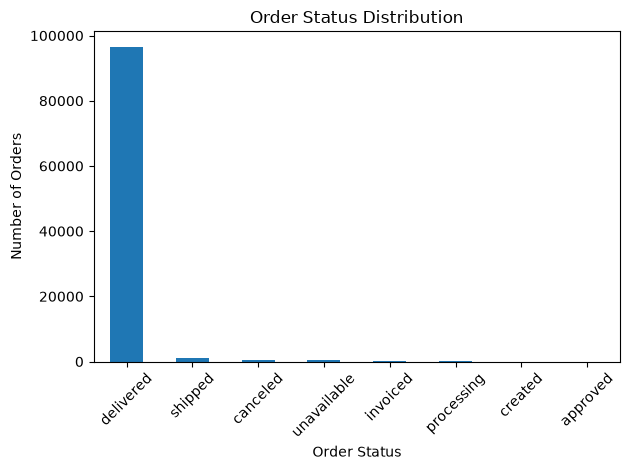

In [4]:
# Visualize the distribution of order status.
order_status = orders["order_status"].value_counts()
order_status.plot(kind="bar")
plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()

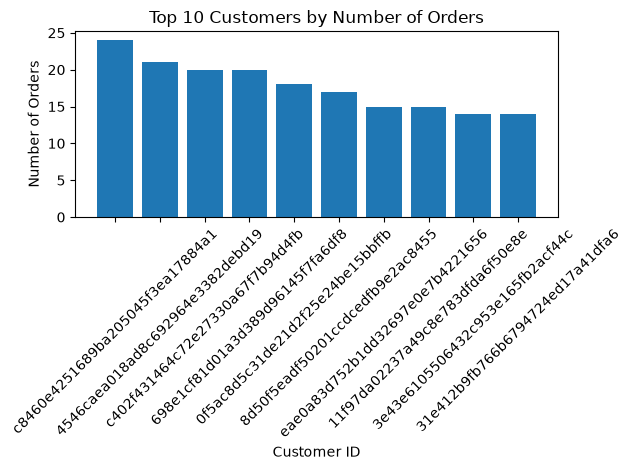

In [5]:
# Bar chart for Top 10 customers by number of orders.
top_10_customers_by_orders = orders_customers_orderItems["customer_unique_id"].value_counts().head(10)
#top_10_customers_by_orders = orders_customers_orderItems.groupby("customer_unique_id")["order_id"].count().nlargest(10)
plt.bar(top_10_customers_by_orders.index, top_10_customers_by_orders.values)
plt.title("Top 10 Customers by Number of Orders")
plt.xlabel("Customer ID")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()

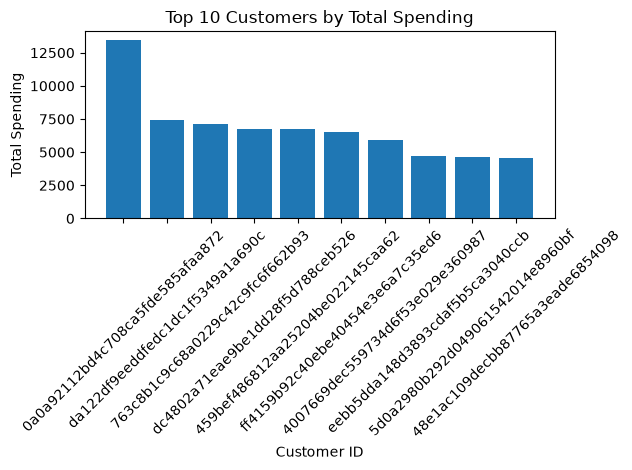

In [6]:
# Bar chart for Top 10 customers by total spending excluding freight charges.
top_10_customers_by_spending = orders_customers_orderItems.groupby("customer_unique_id")["price"].sum().nlargest(10)
plt.bar(top_10_customers_by_spending.index, top_10_customers_by_spending.values)
plt.title("Top 10 Customers by Total Spending")
plt.xlabel("Customer ID")
plt.ylabel("Total Spending")
plt.xticks(rotation=45)
plt.tight_layout()

Text(0.5, 1.0, 'One-time vs Repeat Customers')

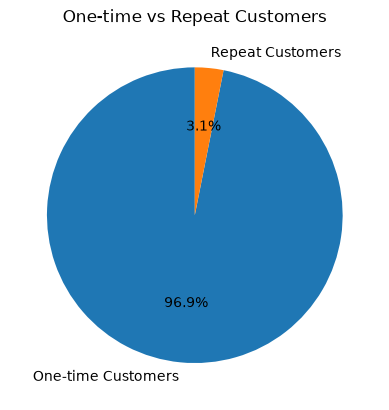

In [7]:
# One-time vs Repeat Customers.
one_time_customers = (orders_customers["customer_unique_id"].value_counts()).values == 1
repeat_customers = (orders_customers["customer_unique_id"].value_counts()).values > 1
plt.pie([one_time_customers.sum(), repeat_customers.sum()], labels=["One-time Customers", "Repeat Customers"], autopct='%1.1f%%', startangle=90)
plt.title("One-time vs Repeat Customers")

Text(0, 0.5, 'Number of Orders')

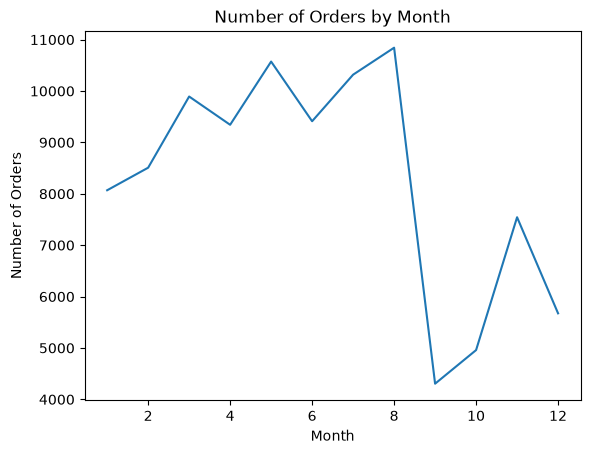

In [8]:
# line chart for number of orders by month.
number_of_orders_by_month = orders.groupby("purchase_month")["order_id"].count()
plt.plot(number_of_orders_by_month)
plt.title("Number of Orders by Month")
plt.xlabel("Month")
plt.ylabel("Number of Orders")

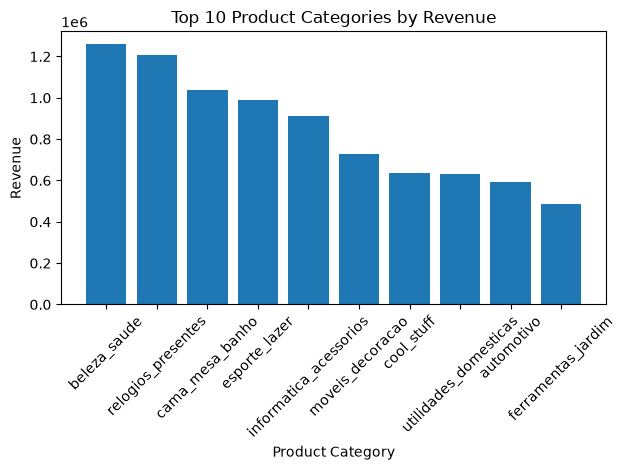

In [9]:
# Top 10 Product Categories by Revenue.
top_10_categories = orderItems_products.groupby("product_category_name")["price"].sum().nlargest(10)
plt.bar(top_10_categories.index, top_10_categories.values)
plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Product Category")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()

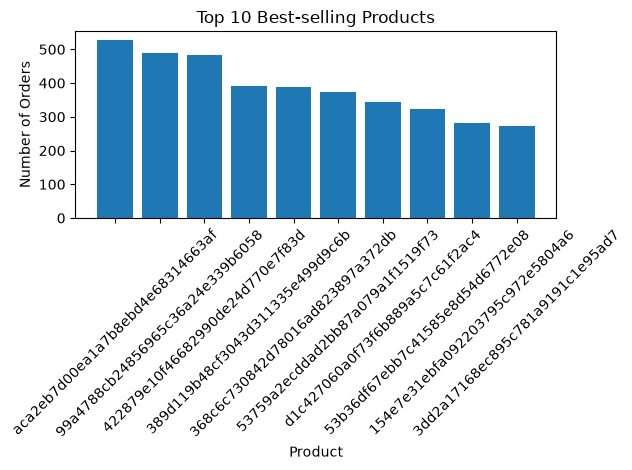

In [10]:
# Find Top 10 Best-selling Products.
top_10_products = orderItems_products["product_id"].value_counts().head(10)
plt.bar(top_10_products.index, top_10_products.values)
plt.title("Top 10 Best-selling Products")
plt.xlabel("Product")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()

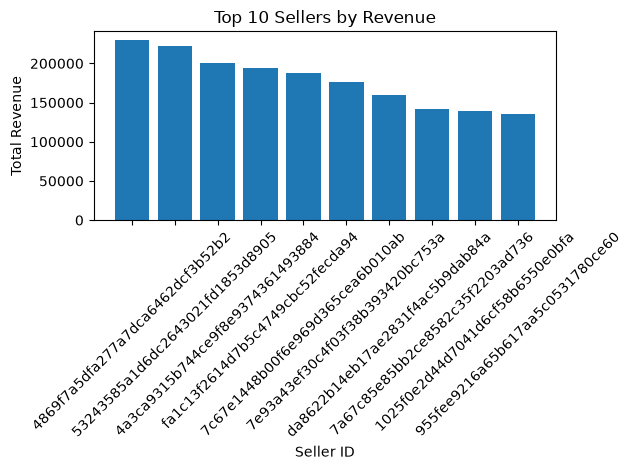

In [11]:
# Top 10 Sellers by Revenue.
top_10_sellers_by_revenue = orderItems_products.groupby("seller_id")["price"].sum().nlargest(10)
plt.bar(top_10_sellers_by_revenue.index,top_10_sellers_by_revenue.values)
plt.title("Top 10 Sellers by Revenue")
plt.xlabel("Seller ID")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()

In [12]:
# Find orders that were delivered after the expected delivery date.
missed_expected_delivery_date = (orders["order_estimated_delivery_date"] - orders["order_delivered_customer_date"])
delayed_orders = missed_expected_delivery_date[missed_expected_delivery_date < pd.Timedelta(0) ]
delayed_orders.index = orders.loc[delayed_orders.index, "order_id"]
delayed_orders= delayed_orders.dt.days.abs()

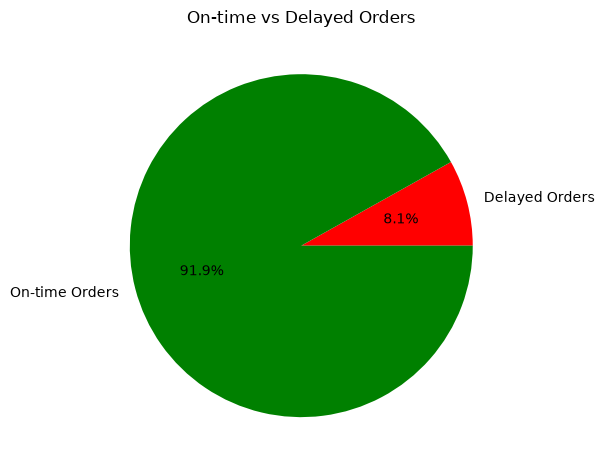

In [13]:
# On-time vs Delayed Orders.
number_of_all_orders = orders[orders["order_status"] == "delivered"]["order_id"].count()
number_of_delayed_orders = delayed_orders.count()
number_of_On_time_orders = number_of_all_orders - number_of_delayed_orders
plt.pie([number_of_delayed_orders,number_of_On_time_orders],labels=["Delayed Orders","On-time Orders"],autopct="%1.1f%%",colors=["red","green"])
plt.title("On-time vs Delayed Orders")
plt.tight_layout()

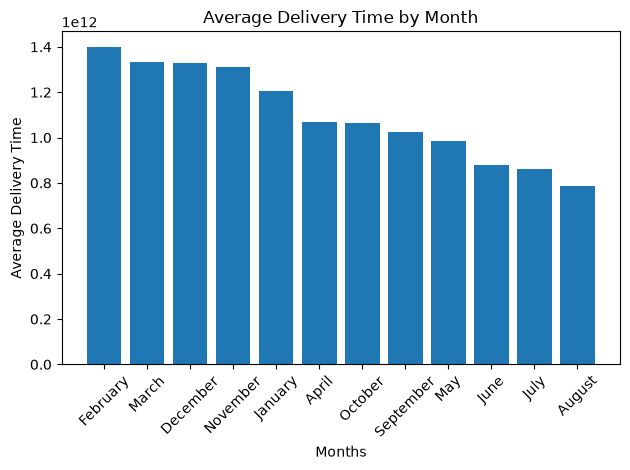

In [14]:
# Average Delivery Time by Month.
orders["delivery_time"] = orders["order_delivered_customer_date"] - orders["order_purchase_timestamp"]
average_delivery_time = orders.groupby("purchase_month_name")["delivery_time"].mean().sort_values(ascending=False)
plt.bar(average_delivery_time.index,average_delivery_time.values)
plt.title("Average Delivery Time by Month")
plt.xlabel("Months")
plt.ylabel("Average Delivery Time")
plt.xticks(rotation=45)
plt.tight_layout()


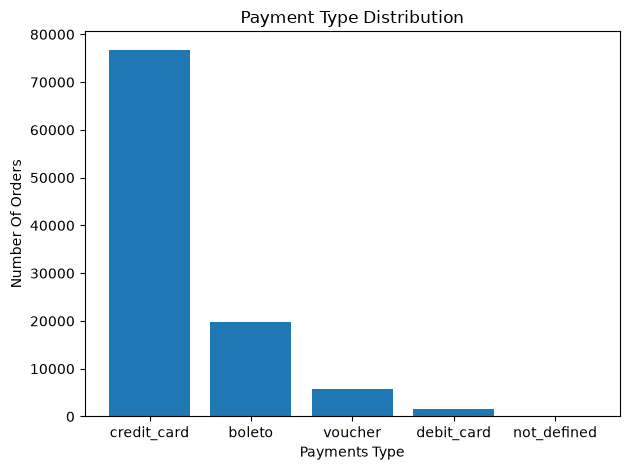

In [15]:
# Payment Type Distribution.
payment_counts = payments["payment_type"].value_counts()
plt.bar(payment_counts.index,payment_counts.values)
plt.title("Payment Type Distribution")
plt.xlabel("Payments Type")
plt.ylabel("Number Of Orders")
plt.tight_layout()

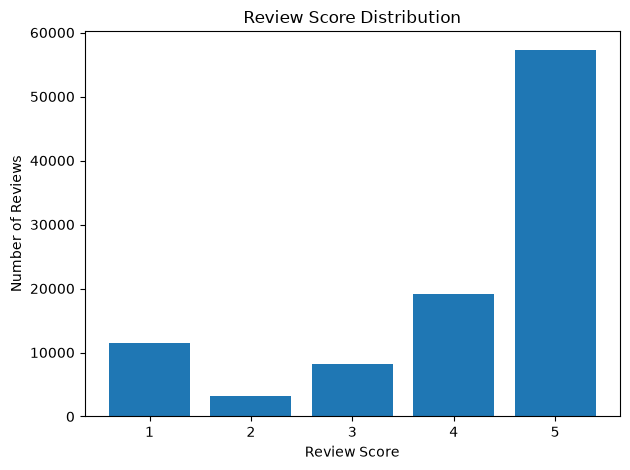

In [16]:
# Review Score Distribution⭐
review_scores = reviews["review_score"].value_counts().sort_index()
plt.bar(review_scores.index, review_scores.values)
plt.title("Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")
plt.tight_layout()

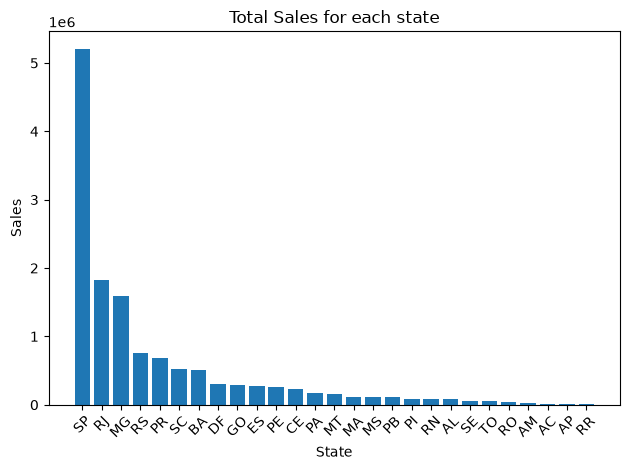

In [17]:
# Find total sales for each state.
sales_by_state = orders_customers_orderItems.groupby("customer_state")["price"].sum().sort_values(ascending=False)
plt.bar(sales_by_state.index, sales_by_state.values)
plt.title("Total Sales for each state")
plt.xlabel("State")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()

# Final Business Insights & Recommendations

## Customer Insights

* The analysis identified a group of repeat customers, with the most frequent customer placing 17 orders. This indicates the presence of customers with repeated purchasing behavior and an opportunity to strengthen customer retention and loyalty strategies.

* The highest-spending customer generated 13,440 in product purchases, excluding freight charges, highlighting the importance of identifying and retaining high-value customers.

## Sales Insights

* Total product sales reached approximately 13.59 million, with an average order value of approximately 137.75. This provides a baseline for evaluating customer spending and order performance.

* The highest-value order generated 13,440 in product sales, showing that a small number of orders can have substantially higher values than the average order.

## Product Insights

* `beleza_saude` was the highest-revenue product category, indicating strong customer demand for beauty and health products.

* The product analysis also revealed a concentration of sales among a relatively small group of products, with the leading product generating 63,885 in revenue and 527 order items.

* Comparing sales quantity and revenue helps distinguish products that generate high demand from products that generate high monetary value.

## Order Insights

* The dataset contains 99,441 orders, with 96,478 recorded as delivered. Delivered orders therefore represent the dominant order status in the dataset.

* Order activity increased substantially between 2016 and 2018, reaching 54,011 orders in 2018 compared with 45,101 in 2017.

* August recorded the highest number of orders with 10,843 orders, followed by May with 10,573 and July with 10,318. September had the lowest monthly volume with 4,305 orders.

## Payment Insights

* Credit cards were the dominant payment method and generated the highest total payment value at 13664.08 million.
* Credit cards also had the highest average payment value among the defined payment methods with 163.32 million.
* Voucher transactions had a noticeably lower average payment value of approximately 65.70 compared with the other defined payment methods.
* One-installment payments represented approximately 50.58% of payment records, making a single installment the most common payment option.

## Review Insights

* Customer feedback was generally positive: 77.07% of ratings were positive (4–5), 8.24% were neutral, and 14.69% were negative.

* A rating of 5 was the most common individual rating, representing 57.78% of all reviews.

* Written comments were provided in 41.3% of reviews, while 58.7% contained no comment.

* Customers giving low ratings were substantially more likely to leave written comments. For example, comments accompanied 76.55% of 1-star reviews compared with 35.85% of 5-star reviews. This suggests that negative feedback is more likely to contain additional qualitative information about customer problems.

## Geographic Insights

* São Paulo had the highest number of customers and orders, making it the largest market by customer and order volume, while Roraima had the lowest volume.

* São Paulo generated 38.28% of total sales, followed by Rio de Janeiro at 13.42% and Minas Gerais at 11.66%. Together, these three states accounted for 63.36% of total sales, showing a strong geographic concentration of revenue.

* Despite São Paulo having the highest customer and order volume, it had the lowest average order value among the states at 124.63. Paraíba had the highest average order value at 215.05.

* Delivery performance varied considerably by geography. São Paulo had the shortest average carrier-to-customer delivery time at approximately 5.5 days, while Roraima had the longest at approximately 24.6 days.

## Seller Insights

* Seller activity was concentrated among a group of high-performing sellers. The leading seller by order volume processed 2,033 order items, while the highest-revenue seller generated approximately 229,473 in product revenue.

* Comparing seller order volume with seller revenue provides a useful way to distinguish sellers with high transaction volume from those generating higher-value sales.

## Delivery Insights

* The average order approval time was approximately 10.42 hours, while the average shipping preparation time was approximately 2.81 hours.

* The average time from carrier handoff to customer delivery was approximately 9 days, while the complete purchase-to-delivery process averaged approximately 13 days.

* Delivery performance differed substantially between states, indicating that geographic location is an important factor when evaluating logistics performance.

## Overall Business Recommendations

* Focus customer-retention initiatives on repeat and high-value customers to increase customer lifetime value.

* Prioritize high-performing product categories and products while continuously monitoring sales quantity versus revenue to identify different types of top-performing products.

* Use the strong sales concentration in São Paulo, Rio de Janeiro, and Minas Gerais to understand the characteristics of the largest markets, while investigating opportunities in states with higher average order values.

* Monitor delivery performance by state and investigate the operational factors behind the large geographic differences in delivery time.

* Maintain strong support for credit-card payments while monitoring the performance and role of alternative payment methods.

* Use low review scores and their associated comments as a signal for identifying customer pain points and improving the overall customer experience.

* Monitor seller performance using both order volume and revenue rather than relying on a single performance metric.

* Use seasonal order patterns to support inventory, seller, and operational planning during high-demand periods.


* Design and implement loyalty and reward programs to incentivize repeat purchases; launch personalized email marketing campaigns to engage customers following their initial purchase. 

* Analyze the reasons behind customer churn to evaluate the post-purchase experience and the quality of the products or services provided.